Run the following command for generating the data in `./data/checkpoint.csv`. It simulates every parameter point until 100 block errors are reached and saves a checkpoint after every chunk of shots, so it can be interrupted and resumed.

```bash
python simulations/cat_qubit_cln/parallel_simulation.py
```

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_FILE = Path("./data/checkpoint.csv")

df = pd.read_csv(CSV_FILE)

In [2]:
df = df.copy()

df["p_block"] = df["num_block_errors"] / df["num_shots"]

# Ruiz et al. conversion: block failure -> average logical failure
# LER per logical qubit after d QEC rounds.
df["p_logical_per_k"] = 1 - (1 - df["p_block"]) ** (1 / df["d"])

# LER per logical qubit per round.
df["p_logical_per_k_per_d"] = df["p_logical_per_k"] / df["d"]

# Status is convenient when plotting partial / resumed simulations.
if "status" not in df.columns:
    df["status"] = "unknown"

df = df.sort_values(["d", "p_ph"]).reset_index(drop=True)


In [3]:
display(df)

,d,p_ph,nbar,post_processing,num_shots,num_block_errors,num_logical_errors,num_chunks,status,p_block,p_logical_per_k,p_logical_per_k_per_d
0,3,0.00005,11.0,True,250000,280,451,1,target_errors_reached,1.120000e-03,3.734728e-04,1.244909e-04
1,3,0.00010,11.0,True,250000,1175,1906,1,target_errors_reached,4.700000e-03,1.569128e-03,5.230425e-04
2,3,0.00020,11.0,True,250000,4156,6743,1,target_errors_reached,1.662400e-02,5.572326e-03,1.857442e-03
3,3,0.00030,11.0,True,250000,8514,13746,1,target_errors_reached,3.405600e-02,1.148336e-02,3.827788e-03
4,3,0.00040,11.0,True,250000,14046,22609,1,target_errors_reached,5.618400e-02,1.909011e-02,6.363371e-03
5,3,0.00050,11.0,True,250000,20039,32196,1,target_errors_reached,8.015600e-02,2.746615e-02,9.155383e-03
6,3,0.00060,11.0,True,250000,26694,42961,1,target_errors_reached,1.067760e-01,3.693974e-02,1.231325e-02
7,3,0.00070,11.0,True,250000,33483,54451,1,target_errors_reached,1.339320e-01,4.680008e-02,1.560003e-02
8,3,0.00080,11.0,True,250000,41070,66660,1,target_errors_reached,1.642800e-01,5.806645e-02,1.935548e-02
9,3,0.00090,11.0,True,250000,47924,78211,1,target_errors_reached,1.916960e-01,6.848130e-02,2.282710e-02


In [4]:
# 95% Wilson confidence interval for the estimated logical error probability, accounting for the finite number of Monte Carlo samples
def wilson_interval(k, n, z=1.959963984540054):
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)

    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denom

    return np.maximum(0, center-half), np.minimum(1, center+half)


block_lo, block_hi = wilson_interval(
    df["num_block_errors"].to_numpy(),
    df["num_shots"].to_numpy(),
)

df["p_block_lo"] = block_lo
df["p_block_hi"] = block_hi

df["p_logical_per_k_lo"] = 1 - (1 - df["p_block_lo"]) ** (1 / df["d"])
df["p_logical_per_k_hi"] = 1 - (1 - df["p_block_hi"]) ** (1 / df["d"])

In [5]:
df_plot = df[(df["num_block_errors"] > 1)]

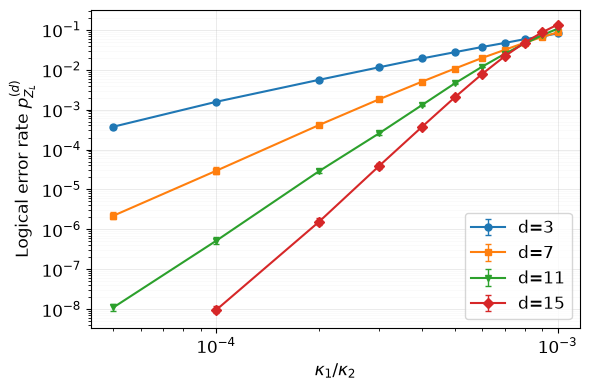

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))

markers = {
    3: "o",
    7: "s",
    11: "v",
    15: "D",
}

for d, g in df_plot.groupby("d"):
    g = g.sort_values("p_ph")
    y = g["p_logical_per_k"].to_numpy()
    yerr = np.vstack([
        y - g["p_logical_per_k_lo"].to_numpy(),
        g["p_logical_per_k_hi"].to_numpy() - y,
    ])
    ax.errorbar(
        g["p_ph"],
        y,
        yerr=yerr,
        marker=markers.get(d, "o"),
        markersize=5,
        linewidth=1.5,
        capsize=2.5,
        capthick=1.0,
        elinewidth=1.0,
        label=f"d={d}",
    )
    
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_xlabel(r"$\kappa_1/\kappa_2$", fontsize=12)
ax.set_ylabel(r"Logical error rate $p_{Z_L}^{(d)}$", fontsize=12)
ax.tick_params(axis="both", which="major",labelsize=10,)
# ax.tick_params(axis='both', which='major', width=3, length=12)  # length is optional
# # Thicker minor ticks
# ax.tick_params(axis='both', which='minor', width=1.5, length=8)  # Adjust as needed
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# Much less intrusive grid
ax.grid(axis="y",which="major",alpha=0.25,linewidth=0.7)
ax.grid(axis="x",which="major",alpha=0.25,linewidth=0.7)
ax.grid(axis="y", which="minor", alpha=0.08, linewidth=0.5)

ax.legend(loc="lower right",fontsize=12)
fig.tight_layout()
fig.savefig("parity_code_cat_noise.pdf", bbox_inches="tight")
plt.show()